# Análise preditiva de resultados da Fórmula 1 com SVM

**Autores:** Ana Raquel da Silva Correia e Nicolas Mariano de Azevedo

**Orientadores:** Fabiano Bezerra e Higor Barreto

Engenharia de Software, Universidade de Mogi das Cruzes

Este notebook mostra cada etapa do experimento e guarda as saídas da execução original no Kaggle. O resumo dos resultados está no [README](../README.md).

## Etapa 1: Importar bibliotecas e definir o caminho do dataset

In [77]:
# Passo 1: Importar biblioteca
import pandas as pd

In [78]:
# Passo 2: Definir o caminho do arquivo
# usa o caminho do Kaggle quando ele existe e, fora de lá, a pasta data/raw do repositório
from pathlib import Path

path_kaggle = Path('/kaggle/input/datasets/patelris/formula-1-complete-dataset-1950-2026/f1_results.csv')
path_local = Path('../data/raw/f1_results.csv')
path_complete = path_kaggle if path_kaggle.exists() else path_local

## Etapa 2: Criar o dataframe

In [79]:
# Passo 1: Criar o DataFrame
df_f1 = pd.read_csv(path_complete)

In [80]:
# Passo 2: Conferir estrutura, nulos e tipos
df_f1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25939 entries, 0 to 25938
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   season            25939 non-null  int64  
 1   round             25939 non-null  int64  
 2   race_name         25939 non-null  object 
 3   driver_id         25939 non-null  object 
 4   driver_name       25939 non-null  object 
 5   constructor_id    25939 non-null  object 
 6   constructor       25939 non-null  object 
 7   grid              25939 non-null  int64  
 8   position          25939 non-null  int64  
 9   points            25939 non-null  float64
 10  laps              25939 non-null  int64  
 11  status            25939 non-null  object 
 12  time              8354 non-null   object 
 13  fastest_lap       8785 non-null   object 
 14  fastest_lap_rank  8785 non-null   float64
dtypes: float64(2), int64(5), object(8)
memory usage: 3.0+ MB


In [81]:
# Passo 3: Ver distribuição bruta da coluna grid
df_f1['grid'].value_counts()

grid
1     1163
7     1162
4     1159
5     1159
9     1159
11    1159
3     1157
10    1157
8     1156
12    1154
2     1153
13    1152
6     1152
14    1147
15    1140
16    1127
17    1116
18    1079
19    1065
20    1015
21     695
22     654
23     452
24     428
25     299
0      267
26     247
27      44
28      29
29      25
30      19
31      18
32      17
33      13
34       1
Name: count, dtype: int64

## Etapa 3: Remover colunas com excesso de dados nulos

As colunas time, fastest_lap e fastest_lap_rank têm menos de 35% dos valores preenchidos, então não vale a pena tentar recuperar.

In [82]:
# Passo 1: Remover as colunas
colunas_para_remover = ['time', 'fastest_lap', 'fastest_lap_rank']
df_f1 = df_f1.drop(columns=colunas_para_remover)

In [83]:
# Passo 2: Conferir resultado
df_f1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25939 entries, 0 to 25938
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   season          25939 non-null  int64  
 1   round           25939 non-null  int64  
 2   race_name       25939 non-null  object 
 3   driver_id       25939 non-null  object 
 4   driver_name     25939 non-null  object 
 5   constructor_id  25939 non-null  object 
 6   constructor     25939 non-null  object 
 7   grid            25939 non-null  int64  
 8   position        25939 non-null  int64  
 9   points          25939 non-null  float64
 10  laps            25939 non-null  int64  
 11  status          25939 non-null  object 
dtypes: float64(1), int64(5), object(6)
memory usage: 2.4+ MB


## Etapa 4: Tratar a largada dos boxes

Quando o grid é 0, o piloto largou dos boxes ou não fez tempo no quali. Se ficasse assim, o modelo ia entender o 0 como “melhor que a pole”, que é o contrário do que acontece de verdade.

Troquei o 0 por um valor fixo (30), que fica atrás de qualquer posição de largada da era moderna da F1, colocando esses pilotos no fim do grid. Usei um valor fixo em vez de calcular o máximo dos dados para que a regra não dependa de nenhuma informação do conjunto de teste.

In [84]:
# Passo 1: Ver quantos pilotos largaram dos boxes (grid = 0)
(df_f1['grid'] == 0).sum()

np.int64(267)

In [85]:
# Passo 2: Mandar quem largou dos boxes pro fim do grid

# valor fixo que representa "largou dos boxes": nenhum grid da era moderna chegou a 30 carros
grid_boxes = 30

# troca todo 0 da coluna grid pelo valor 30
df_f1['grid'] = df_f1['grid'].replace(0, grid_boxes)

In [86]:
# Passo 3: Conferir se não sobrou nenhum 0
print('Pilotos com grid 0 restantes:', (df_f1['grid'] == 0).sum())

Pilotos com grid 0 restantes: 0


## Etapa 5: Criar a variável alvo (target)

Prever a posição exata (1º, 2º, ... 39º) seria difícil demais, e muitas posições têm poucos exemplos. Agrupei em 3 faixas que fazem sentido na F1: pódio (top 3), pontua (4º ao 10º) e fora do top 10. Assim o problema vira uma classificação com 3 classes, e todas têm bastante exemplo.

In [87]:
# Passo 1: Definir a função de classificação
def classificar_resultado(pos):
    if pos <= 3:
        return 'podio'
    elif pos <= 10:
        return 'pontua'
    else:
        return 'fora_top10'

In [88]:
# Passo 2: Aplicar a função e criar a coluna 'resultado'
df_f1['resultado'] = df_f1['position'].apply(classificar_resultado)

In [89]:
# Passo 3: Visualizar a distribuição das categorias
df_f1['resultado'].value_counts()

resultado
fora_top10    14348
pontua         8113
podio          3478
Name: count, dtype: int64

## Etapa 6: Unificar equipes que mudaram de nome

Nas próximas etapas, o modelo vai usar o desempenho da equipe na temporada anterior. Algumas equipes, porém, só trocam de nome e continuam sendo a mesma estrutura, com a mesma fábrica e as mesmas pessoas (Force India → Racing Point → Aston Martin, por exemplo). Se eu usasse o nome direto, a Aston Martin de 2021 apareceria como “equipe nova” e perderia todo o histórico.

Por isso criei a coluna equipe, em que todos os nomes de uma mesma equipe viram um nome só.

In [90]:
# Passo 1: Criar o dicionário de equipes renomeadas
# Este dicionário funciona assim: 'nome no dataset': 'nome único usado para a equipe inteira'
linhagem_equipes = {
    'brawn': 'mercedes',             # Brawn GP (2009) virou Mercedes (2010)
    'bmw_sauber': 'sauber',          # BMW Sauber -> Sauber
    'alfa': 'sauber',                # Alfa Romeo (2019-2023) era a Sauber
    'audi': 'sauber',                # Audi (2026) assumiu a Sauber
    'toro_rosso': 'rb',              # Toro Rosso -> AlphaTauri -> RB
    'alphatauri': 'rb',
    'force_india': 'aston_martin',   # Force India -> Racing Point -> Aston Martin
    'racing_point': 'aston_martin',
    'renault': 'alpine',             # Renault -> Lotus F1 -> Renault -> Alpine
    'lotus_f1': 'alpine',
    'virgin': 'manor',               # Virgin -> Marussia -> Manor
    'marussia': 'manor',
    'lotus_racing': 'caterham',      # Lotus Racing (2010-2011) -> Caterham
}

In [91]:
# Passo 2: Criar a coluna 'equipe'
# se o nome está no dicionário, troca pelo nome único; se não está, mantém o original
df_f1['equipe'] = df_f1['constructor_id'].replace(linhagem_equipes)

In [92]:
# Passo 3: Conferir os nomes das equipes da era moderna
# Os nomes do dicionário precisam ser iguais aos ids do dataset.
# Se aparecer aqui uma equipe renomeada que ficou de fora do dicionário, é só adicionar no Passo 1.
print(df_f1[df_f1['season'] >= 2009]['equipe'].unique())

['mercedes' 'toyota' 'alpine' 'williams' 'rb' 'aston_martin' 'sauber'
 'red_bull' 'ferrari' 'mclaren' 'caterham' 'hrt' 'manor' 'haas' 'cadillac']


## Etapa 7: Criar o histórico do piloto

O SVM só trabalha com números, mas transformar o id do piloto em número não ajuda. Esses números seguem a ordem alfabética e não dizem nada sobre desempenho. Como o SVM calcula distâncias entre os pontos, ele trataria dois pilotos como “parecidos” só porque os números estão próximos.

No lugar do id, criei a feature media_piloto_ano_anterior: a posição média de chegada do piloto na temporada anterior. Ela usa só a temporada anterior, então é uma informação que já existe antes da corrida acontecer. Não há vazamento.

In [93]:
# Passo 1: Calcular a média de posição de cada piloto em cada temporada

# agrupa as linhas por temporada e piloto, e calcula a média da posição final de cada grupo
media_piloto = df_f1.groupby(['season', 'driver_id'])['position'].mean()

# transforma o resultado de volta numa tabela normal, com as colunas season, driver_id e position
media_piloto = media_piloto.reset_index()

# renomeia a coluna 'position' para deixar claro o que ela guarda
media_piloto = media_piloto.rename(columns={'position': 'media_piloto_ano_anterior'})

In [94]:
# Passo 2: Deslocar a média para a temporada seguinte
# soma 1 na temporada: a média que o piloto teve em 2022 vira a informação usada nas corridas de 2023
media_piloto['season'] = media_piloto['season'] + 1

In [95]:
# Passo 3: Juntar a média no dataframe principal
# casa as linhas pela temporada e pelo piloto
# how='left' mantém todas as linhas do df_f1; quem não correu no ano anterior fica com valor vazio (NaN)
df_f1 = df_f1.merge(media_piloto, on=['season', 'driver_id'], how='left')

## Etapa 8: Criar o histórico da equipe

Mesma ideia da etapa anterior, agora para a equipe: media_equipe_ano_anterior é a posição média de chegada dos carros da equipe na temporada anterior. Ela usa a coluna equipe criada na Etapa 6, então equipes que só mudaram de nome mantêm o histórico.

In [96]:
# Passo 1: Calcular a média de posição de cada equipe em cada temporada
media_equipe = df_f1.groupby(['season', 'equipe'])['position'].mean()
media_equipe = media_equipe.reset_index()
media_equipe = media_equipe.rename(columns={'position': 'media_equipe_ano_anterior'})

In [97]:
# Passo 2: Deslocar a média para a temporada seguinte
media_equipe['season'] = media_equipe['season'] + 1

In [98]:
# Passo 3: Juntar a média no dataframe principal
df_f1 = df_f1.merge(media_equipe, on=['season', 'equipe'], how='left')

## Etapa 9: Remover colunas com vazamento de dados

Essas colunas só existem depois que a corrida acaba: pontos, voltas completadas, status de abandono e a própria posição. Se ficassem, o modelo ia “colar” a resposta. O resultado seria ótimo, mas não serviria para nada na prática, porque antes da corrida essas informações não existem.

A coluna position só pode ser removida aqui, depois de ter sido usada nas Etapas 7 e 8 para calcular as médias da temporada anterior.

In [99]:
# Passo 1: Identificar quais colunas vazam informação do resultado da própria corrida
colunas_vazamento = ['position', 'points', 'laps', 'status']

In [100]:
# Passo 2: Remover essas colunas
df_f1 = df_f1.drop(columns=colunas_vazamento)

In [101]:
# Passo 3: Conferir quais colunas sobraram
df_f1.columns

Index(['season', 'round', 'race_name', 'driver_id', 'driver_name',
       'constructor_id', 'constructor', 'grid', 'resultado', 'equipe',
       'media_piloto_ano_anterior', 'media_equipe_ano_anterior'],
      dtype='object')

## Etapa 10: Filtrar a era moderna (2010 em diante)

A F1 dos anos 50 a 2000 tinha grids com mais de 30 carros, muitas quebras e regras bem diferentes, então misturar tudo ensinaria padrões que não valem mais. Desde 2010 os 10 primeiros marcam pontos, então a classe “pontua” corresponde exatamente ao sistema de pontuação. Menos linhas também deixam o SVM bem mais rápido.

O filtro só é feito agora porque a temporada de 2009 foi necessária nas Etapas 7 e 8 para calcular o histórico das corridas de 2010.

In [102]:
# Passo 1: Manter só as temporadas de 2010 em diante
df_f1 = df_f1[df_f1['season'] >= 2010].copy()

In [103]:
# Passo 2: Conferir a primeira e a última temporada que sobraram
print('Primeira temporada:', df_f1['season'].min())
print('Última temporada:', df_f1['season'].max())
print('Total de linhas:', len(df_f1))

Primeira temporada: 2010
Última temporada: 2026
Total de linhas: 6977


## Etapa 11: Dividir em treino e teste (por temporada)

Não usei divisão aleatória, porque o modelo poderia treinar com corridas de 2024 e testar em 2015, ou seja, usar o futuro para prever o passado. Separando por temporada (até 2023 no treino, 2024 em diante no teste), a avaliação simula o uso real: prever corridas novas com base no histórico.

In [104]:
# Passo 1: Garantir que os dados estão em ordem cronológica
df_f1 = df_f1.sort_values(['season', 'round']).reset_index(drop=True)

In [105]:
# Passo 2: Separar por temporada (temporadas antigas pra treinar, recentes pra testar)
treino = df_f1[df_f1['season'] < 2024].copy()
teste = df_f1[df_f1['season'] >= 2024].copy()

print('Linhas de treino:', len(treino))
print('Linhas de teste:', len(teste))

Linhas de treino: 5953
Linhas de teste: 1024


## Etapa 12: Preencher o histórico de estreantes

Pilotos estreantes, pilotos que voltaram depois de um ano fora e equipes novas (como a Haas em 2016) não têm temporada anterior, então ficaram com valor vazio. O SVM não aceita valores vazios.

Preenchi esses casos com a mediana do treino, um valor “do meio da tabela”, que é uma suposição neutra para quem ainda não tem histórico. A mediana é calculada só com o treino, para o teste não influenciar nada.

In [106]:
# Passo 1: Ver quantos valores vazios existem em cada parte
colunas_historico = ['media_piloto_ano_anterior', 'media_equipe_ano_anterior']

print('Vazios no treino:')
print(treino[colunas_historico].isnull().sum())
print('Vazios no teste:')
print(teste[colunas_historico].isnull().sum())

Vazios no treino:
media_piloto_ano_anterior    1111
media_equipe_ano_anterior     156
dtype: int64
Vazios no teste:
media_piloto_ano_anterior    94
media_equipe_ano_anterior     6
dtype: int64


In [107]:
# Passo 2: Calcular a mediana de cada coluna usando SÓ o treino
mediana_piloto = treino['media_piloto_ano_anterior'].median()
mediana_equipe = treino['media_equipe_ano_anterior'].median()

print('Mediana piloto:', mediana_piloto)
print('Mediana equipe:', mediana_equipe)

Mediana piloto: 10.454044117647058
Mediana equipe: 11.272727272727273


In [108]:
# Passo 3: Preencher os vazios do treino e do teste com as medianas do treino
# fillna troca todo valor vazio (NaN) da coluna pelo valor informado
treino['media_piloto_ano_anterior'] = treino['media_piloto_ano_anterior'].fillna(mediana_piloto)
treino['media_equipe_ano_anterior'] = treino['media_equipe_ano_anterior'].fillna(mediana_equipe)

teste['media_piloto_ano_anterior'] = teste['media_piloto_ano_anterior'].fillna(mediana_piloto)
teste['media_equipe_ano_anterior'] = teste['media_equipe_ano_anterior'].fillna(mediana_equipe)

In [109]:
# Passo 4: Conferir que não sobrou nenhum vazio
print(treino[colunas_historico].isnull().sum())
print(teste[colunas_historico].isnull().sum())

media_piloto_ano_anterior    0
media_equipe_ano_anterior    0
dtype: int64
media_piloto_ano_anterior    0
media_equipe_ano_anterior    0
dtype: int64


## Etapa 13: Separar X (atributos) e y (alvo)

Usei três features: a posição de largada, o histórico do piloto e o histórico da equipe.

season e round ficaram de fora. A temporada do teste (2024+) é sempre maior que qualquer temporada do treino, então o modelo teria que extrapolar um valor que nunca viu. Nenhuma das duas diz nada sobre quem é rápido.

In [110]:
# Passo 1: Definir as features e separar treino/teste
features = ['grid', 'media_piloto_ano_anterior', 'media_equipe_ano_anterior']

X_train = treino[features]
y_train = treino['resultado']

X_test = teste[features]
y_test = teste['resultado']

X_train.head()

,grid,media_piloto_ano_anterior,media_equipe_ano_anterior
0,3,9.823529,9.794118
1,2,10.100000,9.794118
2,4,9.705882,10.411765
3,1,6.882353,7.029412
4,5,8.235294,4.882353


## Etapa 14: Padronizar a escala

O SVM calcula distâncias entre os pontos, então features com números maiores dominariam features com números menores. Padronizando, todas ficam na mesma escala e pesam de forma justa. O padronizador é ajustado só no treino e depois aplicado no teste.

In [111]:
# Passo 1: Importar biblioteca
from sklearn.preprocessing import StandardScaler

In [112]:
# Passo 2: Criar o objeto padronizador
scaler = StandardScaler()

In [113]:
# Passo 3: Ajustar e transformar o treino
X_train_scaled = scaler.fit_transform(X_train)

In [114]:
# Passo 4: Aplicar a mesma transformação no teste
X_test_scaled = scaler.transform(X_test)

## Etapa 15: Treinar o modelo baseline (SVM)

Usei class_weight='balanced' porque as classes estão desbalanceadas (há muito mais “fora_top10” do que “podio”). Sem isso, o modelo tende a chutar a classe maior e quase nunca prever pódio. Essa escolha foi testada na Etapa 18.

In [115]:
# Passo 1: Importar biblioteca
from sklearn.svm import SVC

In [116]:
# Passo 2: Criar e treinar o modelo
modelo = SVC(kernel='rbf', class_weight='balanced')
modelo.fit(X_train_scaled, y_train)

SVC(class_weight='balanced')

In [117]:
# Passo 3: Conferir que treinou
print('Modelo treinado!')
print('Classes aprendidas:', modelo.classes_)

Modelo treinado!
Classes aprendidas: ['fora_top10' 'podio' 'pontua']


## Etapa 16: Avaliar o modelo baseline


In [118]:
# Passo 1: Prever no teste
y_pred = modelo.predict(X_test_scaled)

In [119]:
# Passo 2: Relatório de classificação
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

  fora_top10       0.84      0.72      0.77       514
       podio       0.54      0.89      0.67       153
      pontua       0.59      0.54      0.56       357

    accuracy                           0.68      1024
   macro avg       0.65      0.72      0.67      1024
weighted avg       0.70      0.68      0.68      1024



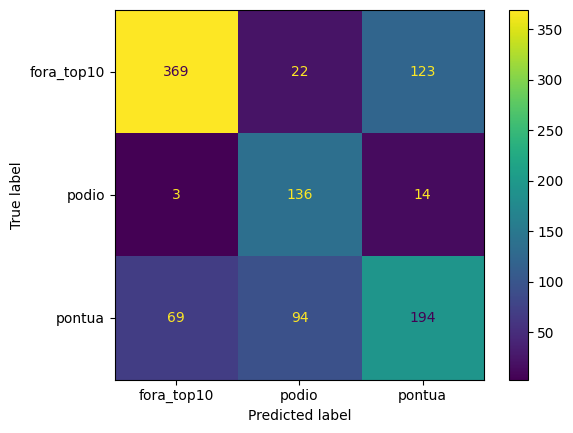

In [120]:
# Passo 3: Matriz de confusão como gráfico
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=modelo.classes_)

In [121]:
# Passo 4: Comparar quantas vezes cada classe foi prevista com quantas existem de verdade
print('Previsto pelo modelo:')
print(pd.Series(y_pred).value_counts())
print('Real no teste:')
print(y_test.value_counts())

Previsto pelo modelo:
fora_top10    441
pontua        331
podio         252
Name: count, dtype: int64
Real no teste:
resultado
fora_top10    514
pontua        357
podio         153
Name: count, dtype: int64


O modelo previu 252 pódios, mas só existem 153 no teste. O balanceamento das classes fez o modelo prever pódio em excesso.

## Etapa 17: Comparar com uma regra simples (só a posição de largada)

Na F1 quem larga na frente costuma terminar na frente, então o grid sozinho já explica muita coisa. Para saber se o SVM está aprendendo algo a mais, comparei com uma regra bem simples: o piloto termina na mesma faixa em que largou (largou no top 3 → pódio, largou do 4º ao 10º → pontua, e assim por diante). Se o SVM não for melhor que isso, o modelo não está agregando muito.

In [122]:
# Passo 1: Aplicar a mesma função do target, mas usando o grid no lugar da posição final
y_pred_regra = teste['grid'].apply(classificar_resultado)

In [123]:
# Passo 2: Relatório da regra simples
print(classification_report(y_test, y_pred_regra))

              precision    recall  f1-score   support

  fora_top10       0.80      0.80      0.80       514
       podio       0.71      0.71      0.71       153
      pontua       0.64      0.64      0.64       357

    accuracy                           0.73      1024
   macro avg       0.72      0.72      0.72      1024
weighted avg       0.73      0.73      0.73      1024



## Etapa 18: Grid Search (treinar com otimização de hiperparâmetros)

Na validação cruzada usei TimeSeriesSplit em vez do padrão. O padrão misturaria as temporadas, e o modelo acabaria validando corridas antigas com treino em corridas mais novas, o que contradiz a divisão por temporada da Etapa 11. Com o TimeSeriesSplit, cada fold sempre treina no passado e valida no período seguinte.

A busca foi dividida em duas grades, porque o kernel linear não usa o parâmetro gamma. Assim ele não é treinado várias vezes com o mesmo resultado:

Grade 1 (linear): 4 valores de C × 2 de class_weight = 8 combinações
Grade 2 (rbf e sigmoid): 2 kernels × 4 valores de C × 4 de gamma × 2 de class_weight = 64 combinações

No total, são 72 combinações × 5 folds = 360 treinos. O n_jobs=-1 usa todos os núcleos do processador para a busca terminar mais rápido.

In [124]:
# Passo 1: Importar bibliotecas
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

In [125]:
# Passo 2: Definir os valores para cada parâmetro
# São duas grades separadas, porque o kernel linear não usa gamma
param_grid = [
    # Grade 1: kernel linear, sem gamma
    {
        'kernel': ['linear'],
        'C': [0.1, 1, 10, 100],
        'class_weight': ['balanced', None]
    },
    # Grade 2: kernels que usam gamma
    {
        'kernel': ['rbf', 'sigmoid'],
        'C': [0.1, 1, 10, 100],
        'gamma': [0.001, 0.01, 0.1, 1],
        'class_weight': ['balanced', None]
    }
]

In [126]:
# Passo 3: Montar a busca
grid = GridSearchCV(
    SVC(),
    param_grid,
    cv=TimeSeriesSplit(n_splits=5),
    scoring='f1_macro',
    n_jobs=-1
)

In [127]:
# Passo 4: Executar a busca
grid.fit(X_train_scaled, y_train)

GridSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None),
             estimator=SVC(), n_jobs=-1,
             param_grid=[{'C': [0.1, 1, 10, 100],
                          'class_weight': ['balanced', None],
                          'kernel': ['linear']},
                         {'C': [0.1, 1, 10, 100],
                          'class_weight': ['balanced', None],
                          'gamma': [0.001, 0.01, 0.1, 1],
                          'kernel': ['rbf', 'sigmoid']}],
             scoring='f1_macro')

## Etapa 19: Melhor modelo, melhores parâmetros e score de validação

In [128]:
print('Melhores parâmetros:', grid.best_params_)
print('Melhor f1_macro (validação):', grid.best_score_)

Melhores parâmetros: {'C': 10, 'class_weight': None, 'gamma': 0.1, 'kernel': 'rbf'}
Melhor f1_macro (validação): 0.6644325116520278


## Etapa 20: Avaliar o modelo otimizado no teste

In [129]:
# Passo 1: Prever no teste com o melhor modelo
melhor_modelo = grid.best_estimator_
y_pred_otimizado = melhor_modelo.predict(X_test_scaled)

In [130]:
# Passo 2: Relatório de classificação
print(classification_report(y_test, y_pred_otimizado))

              precision    recall  f1-score   support

  fora_top10       0.78      0.82      0.80       514
       podio       0.72      0.69      0.70       153
      pontua       0.62      0.59      0.60       357

    accuracy                           0.72      1024
   macro avg       0.71      0.70      0.70      1024
weighted avg       0.72      0.72      0.72      1024



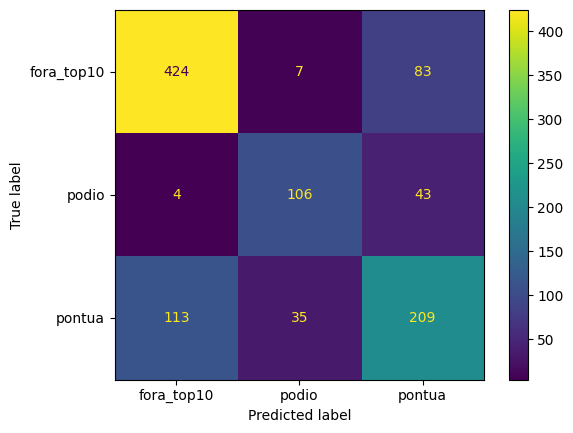

In [131]:
# Passo 3: Matriz de confusão como gráfico
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_otimizado, labels=melhor_modelo.classes_)

In [132]:
# Passo 4: Comparar quantas vezes cada classe foi prevista com quantas existem de verdade
print('Previsto pelo modelo otimizado:')
print(pd.Series(y_pred_otimizado).value_counts())
print('Real no teste:')
print(y_test.value_counts())

Previsto pelo modelo otimizado:
fora_top10    541
pontua        335
podio         148
Name: count, dtype: int64
Real no teste:
resultado
fora_top10    514
pontua        357
podio         153
Name: count, dtype: int64


## Etapa 21: Comparar regra simples vs baseline vs otimizado

In [133]:
print("=== Regra simples (só grid) ===")
print(classification_report(y_test, y_pred_regra))

print("=== Modelo baseline (sem otimização) ===")
print(classification_report(y_test, y_pred))

print("=== Modelo otimizado (GridSearch) ===")
print(classification_report(y_test, y_pred_otimizado))

=== Regra simples (só grid) ===
              precision    recall  f1-score   support

  fora_top10       0.80      0.80      0.80       514
       podio       0.71      0.71      0.71       153
      pontua       0.64      0.64      0.64       357

    accuracy                           0.73      1024
   macro avg       0.72      0.72      0.72      1024
weighted avg       0.73      0.73      0.73      1024

=== Modelo baseline (sem otimização) ===
              precision    recall  f1-score   support

  fora_top10       0.84      0.72      0.77       514
       podio       0.54      0.89      0.67       153
      pontua       0.59      0.54      0.56       357

    accuracy                           0.68      1024
   macro avg       0.65      0.72      0.67      1024
weighted avg       0.70      0.68      0.68      1024

=== Modelo otimizado (GridSearch) ===
              precision    recall  f1-score   support

  fora_top10       0.78      0.82      0.80       514
       podio      

In [134]:
# Resumo em uma tabela só com o f1_macro de cada um
from sklearn.metrics import f1_score

resumo = pd.DataFrame({
    'modelo': ['Regra simples', 'SVM baseline', 'SVM otimizado'],
    'f1_macro': [
        f1_score(y_test, y_pred_regra, average='macro'),
        f1_score(y_test, y_pred, average='macro'),
        f1_score(y_test, y_pred_otimizado, average='macro')
    ]
})
resumo

,modelo,f1_macro
0,Regra simples,0.717258
1,SVM baseline,0.669444
2,SVM otimizado,0.704052


In [135]:
# Porcentagem de pilotos em que o SVM otimizado e a regra simples deram a mesma previsão
# .values tira o índice da regra, para comparar posição por posição com a previsão do SVM
concordancia = (y_pred_otimizado == y_pred_regra.values).mean()
print('Concordância entre SVM e regra simples:', round(concordancia * 100, 1), '%')

Concordância entre SVM e regra simples: 85.9 %


In [136]:
# Olhar só os pilotos em que o SVM e a regra deram previsões diferentes
# True onde as duas previsões são diferentes, False onde são iguais
diferentes = y_pred_otimizado != y_pred_regra.values

# Dos casos diferentes, quantos o SVM acertou
acertos_svm = (y_pred_otimizado[diferentes] == y_test.values[diferentes]).sum()

# Dos casos diferentes, quantos a regra acertou
acertos_regra = (y_pred_regra.values[diferentes] == y_test.values[diferentes]).sum()

print('Casos em que discordam:', diferentes.sum())
print('Acertos do SVM nesses casos:', acertos_svm)
print('Acertos da regra nesses casos:', acertos_regra)

Casos em que discordam: 144
Acertos do SVM nesses casos: 65
Acertos da regra nesses casos: 75


Nos 144 casos em que o SVM e a regra discordam, a regra acertou 75 e o SVM acertou 65. Quando o modelo tenta corrigir a posição de largada usando o histórico da temporada anterior, ele erra um pouco mais do que acerta.

## Etapa 22: Conclusão

O SVM otimizado (kernel rbf, C=10, gamma=0,1, sem balanceamento de classes) chegou a um f1_macro de 0,70 no teste, praticamente empatado com a regra simples baseada só na posição de largada (0,72). O score de validação (0,66) ficou próximo do de teste, então o modelo não está sofrendo overfitting.

Os principais aprendizados foram:

O grid concentra quase toda a informação disponível antes da corrida. Ele vem do quali da própria etapa e reflete a velocidade atual do carro e do piloto. O SVM concorda com a regra simples em 85,9% das previsões. Nos 144 casos em que discordam, a regra acertou 75 e o SVM acertou 65, o que explica a pequena diferença final entre os dois.
O histórico da temporada anterior acrescenta pouco. Ele é em grande parte redundante com o grid, que é uma informação mais atualizada. Quando os dois apontam para lados diferentes, o grid costuma estar certo.
O balanceamento de classes atrapalhou neste problema. Com class_weight='balanced', o modelo previu 252 pódios para 153 reais. Sem balanceamento, previu 148, e o f1_macro subiu de 0,67 para 0,70.
O kernel rbf foi melhor que o linear e o sigmoid, o que indica uma relação não linear entre as features e o resultado. A busca testou valores de C de 0,1 a 100 e de gamma de 0,001 a 1, e os melhores valores (C=10, gamma=0,1) ficaram no meio dessas faixas.

Por fim, o modelo classifica cada piloto isoladamente e não sabe que cada corrida tem exatamente 3 pódios e 7 pilotos pontuando. A regra simples respeita essa estrutura por construção, o que explica parte da sua vantagem. Melhorias possíveis seriam features que o grid não captura, como a dificuldade de ultrapassagem de cada pista, ou um modelo que ordene os pilotos dentro de cada corrida em vez de classificá-los um a um.